# EDA do B2W-Reviews01

Exploração do arquivo bruto `data/raw/B2W-Reviews01.csv` (procedência, licença e hashes em
`docs/data_manifest.md`). O objetivo não é colecionar gráficos: cada seção responde a uma pergunta
e termina numa **decisão** para a limpeza (sub-etapa 1.5) ou para o modelo (Etapa 2). As decisões
estão reunidas na última seção.

A estrutura segue os 5 Vs do tutorial: **volume** (seção 1), **veracidade** (seções 2 a 5),
**variedade** (seção 6). Velocidade e valor já estão respondidos: o B2W é uma fotografia histórica
(jan. a mai. de 2018), lida em lote, e o valor está no `docs/charter.md`.

**Dois cuidados:**

- **Vazamento.** Esta EDA olha o arquivo inteiro, que inclui o futuro conjunto de teste. Isso vale
  para regras de *qualidade de dados* (o dedupe precisa vir antes do split), mas nenhuma decisão de
  modelagem é ajustada a estes números.
- **Privacidade.** As colunas de perfil do avaliador saem logo na leitura, então nenhuma saída deste
  notebook consegue exibi-las. Exemplos de possíveis dados pessoais aparecem mascarados.

Este notebook só **lê** `data/raw`. A limpeza de verdade vai para `src/` com testes, na 1.5.

In [14]:
import re
import unicodedata
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap

# O VS Code roda o notebook a partir de notebooks/; procurar o pyproject.toml acha a raiz do
# projeto de qualquer pasta, sem caminho fixo da máquina.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
RAW_CSV = ROOT / "data" / "raw" / "B2W-Reviews01.csv"
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Uma cor só para série única e uma rampa azul (claro -> escuro) para magnitude: cor diferente
# em cada gráfico sugeriria categorias que não existem.
BLUE = "#2a78d6"
BLUE_RAMP = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
plt.rcParams.update(
    {
        "figure.facecolor": "#fcfcfb",
        "axes.facecolor": "#fcfcfb",
        "axes.edgecolor": "#c3c2b7",
        "axes.labelcolor": "#52514e",
        "axes.titlecolor": "#0b0b0b",
        "axes.titlesize": 11,
        "axes.titleweight": "bold",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.axisbelow": True,
        "grid.color": "#e1e0d9",
        "grid.linewidth": 0.6,
        "xtick.color": "#898781",
        "ytick.color": "#898781",
        "font.size": 10,
        "figure.dpi": 100,
        "savefig.dpi": 150,
        "savefig.bbox": "tight",
    }
)
pd.set_option("display.max_colwidth", 90)


def fmt(n: float) -> str:
    """Número com ponto de milhar, como se escreve em português."""
    return f"{n:,.0f}".replace(",", ".")

## 0. Leitura

O separador é **vírgula** (o README do repositório original diz ponto e vírgula, mas o arquivo
mostra outra coisa; ver o manifesto). `product_id` é lido como texto porque é um identificador,
não um número: lido como inteiro, um zero à esquerda sumiria.

In [15]:
PERSONAL_COLUMNS = ["reviewer_id", "reviewer_birth_year", "reviewer_gender", "reviewer_state"]

raw = pd.read_csv(RAW_CSV, sep=",", dtype={"product_id": str}, low_memory=False)
print(f"bruto: {fmt(len(raw))} linhas x {raw.shape[1]} colunas")

# Os dados pessoais saem antes de qualquer análise: a EDA não precisa deles, e assim nenhuma
# célula abaixo consegue exibi-los por acidente.
df = raw.drop(columns=PERSONAL_COLUMNS)
del raw
print("colunas mantidas:", ", ".join(df.columns))

bruto: 132.373 linhas x 14 colunas
colunas mantidas: submission_date, product_id, product_name, product_brand, site_category_lv1, site_category_lv2, review_title, overall_rating, recommend_to_a_friend, review_text


## 1. Volume: quanto texto temos e de que tamanho?

**Pergunta:** o corpus é suficiente para treinar em CPU, e de que tamanho é uma resenha típica?
O tamanho define o contexto máximo do Transformer (o `block_size`): contexto grande custa
memória e tempo de forma quadrática na atenção.

In [16]:
has_text = df["review_text"].notna()
df["n_words"] = df["review_text"].fillna("").str.split().str.len()

print("resenhas com texto:", fmt(has_text.sum()))
print("palavras no corpus:", fmt(df.loc[has_text, "n_words"].sum()))
print("memória do DataFrame:", round(df.memory_usage(deep=True).sum() / 1e6), "MB")
df.loc[has_text, "n_words"].describe(percentiles=[0.5, 0.9, 0.95, 0.99]).round(1)

resenhas com texto: 129.098
palavras no corpus: 2.972.180
memória do DataFrame: 101 MB


count    129098.0
mean         23.0
std          22.2
min           1.0
50%          16.0
90%          45.0
95%          62.0
99%         112.0
max         795.0
Name: n_words, dtype: float64

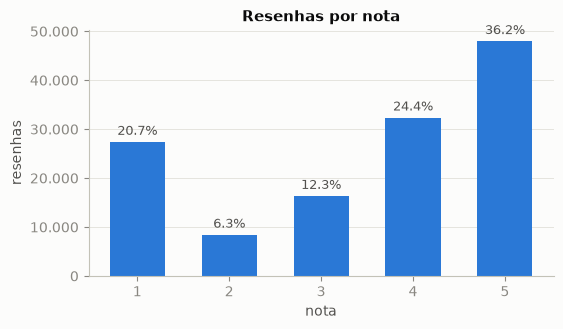

In [17]:
rating_counts = df["overall_rating"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(6, 3.2))
bars = ax.bar(rating_counts.index, rating_counts.values, color=BLUE, width=0.6)
ax.bar_label(bars, labels=[f"{100 * v / len(df):.1f}%" for v in rating_counts.values],
             padding=3, color="#52514e", fontsize=9)
ax.set_title("Resenhas por nota")
ax.set_xlabel("nota")
ax.set_ylabel("resenhas")
ax.yaxis.set_major_formatter(lambda v, _: fmt(v))
ax.grid(axis="x", visible=False)
fig.savefig(FIG_DIR / "eda_ratings.png")
plt.show()

In [18]:
with_text = df[has_text]
length_by_rating = with_text.groupby("overall_rating")["n_words"].describe(
    percentiles=[0.5, 0.95]
)[["count", "50%", "95%", "max"]]
length_by_rating.columns = ["resenhas", "mediana", "p95", "máximo"]
length_by_rating.astype(int)

,resenhas,mediana,p95,máximo
overall_rating,,,,
1,25646,25,87,628
2,8126,23,79,334
3,16010,17,62,795
4,31987,14,47,386
5,47329,14,46,696


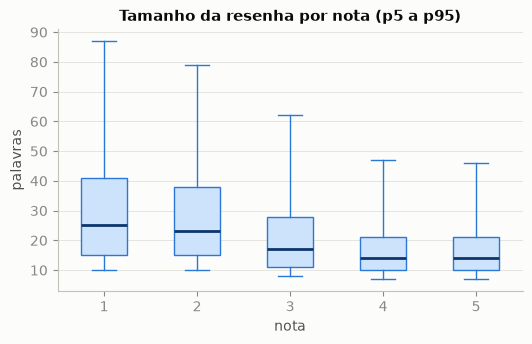

resenhas com até 2 palavras: 399


In [19]:
fig, ax = plt.subplots(figsize=(6, 3.4))
groups = [with_text.loc[with_text["overall_rating"] == r, "n_words"] for r in range(1, 6)]
# Bigodes em p5 e p95 e sem pontos extremos: com resenhas de até ~800 palavras, os extremos
# esmagariam a caixa e esconderiam a diferença entre as notas.
ax.boxplot(groups, tick_labels=[str(r) for r in range(1, 6)], whis=(5, 95), showfliers=False,
           patch_artist=True, widths=0.5,
           boxprops={"facecolor": "#cde2fb", "edgecolor": BLUE},
           medianprops={"color": "#0d366b", "linewidth": 2},
           whiskerprops={"color": BLUE}, capprops={"color": BLUE})
ax.set_title("Tamanho da resenha por nota (p5 a p95)")
ax.set_xlabel("nota")
ax.set_ylabel("palavras")
ax.grid(axis="x", visible=False)
fig.savefig(FIG_DIR / "eda_length_by_rating.png")
plt.show()

print("resenhas com até 2 palavras:", fmt((with_text["n_words"] <= 2).sum()))

**O que os números dizem**

- São cerca de **3 milhões de palavras** em ~129 mil resenhas, e o DataFrame inteiro cabe em
  poucas centenas de MB de memória. Para um Transformer pequeno em CPU, é corpus suficiente;
  não precisa de leitura em lotes do disco.
- A resenha típica é **curta**: mediana de 16 palavras, p95 de 62 e p99 de 112. Há uma cauda longa
  (máximo perto de 800).
- **Resenhas negativas são mais longas** (mediana 25 palavras na nota 1 contra 14 nas notas 4 e 5).
  Faz sentido: quem reclama conta a história (atraso, troca, atendimento). O modelo vai precisar
  gerar textos mais longos para notas baixas, e com menos exemplos de nota 2.

**Decisão**

- Nenhum corte de tamanho na limpeza. O corte é feito na Etapa 2, **em tokens**, depois do BPE.
  Como referência: com ~1,3 a 1,5 tokens por palavra, um contexto de 128 tokens cobre por volta
  de 95% das resenhas inteiras.
- Resenhas muito curtas ("muito bom") ficam: são resenhas legítimas, e o usuário-alvo também
  precisa delas.

## 2. Veracidade: o que está faltando?

In [20]:
missing = df.drop(columns="n_words").isna().sum()
pd.DataFrame({"nulos": missing, "fração (%)": (100 * missing / len(df)).round(1)}).sort_values(
    "nulos", ascending=False
)

,nulos,fração (%)
product_brand,91391,69.0
site_category_lv2,4013,3.0
review_text,3275,2.5
review_title,302,0.2
product_name,84,0.1
recommend_to_a_friend,18,0.0
site_category_lv1,6,0.0
submission_date,0,0.0
product_id,0,0.0
overall_rating,0,0.0


In [21]:
title_only = df["review_text"].isna() & df["review_title"].notna()
print("sem texto, mas com título:", fmt(title_only.sum()))

sem texto, mas com título: 3.203


**Decisão**

- As **3.275 linhas sem `review_text` saem**. O texto é o alvo da geração; sem ele não há exemplo.
  Quase todas têm título (3.203), mas usar o título no lugar do texto misturaria duas tarefas
  (ver seção 8).
- `product_brand` (69% nulo) e `site_category_lv2` não são usados na v1, então os nulos deles não
  pedem tratamento.
- `product_id` e `overall_rating` não têm nulos: o split e o condicionamento estão garantidos.

## 3. Veracidade: duplicatas

**Pergunta:** há resenhas repetidas, e de que tipo? Isso importa por dois motivos do charter:
duplicata entre treino e teste é **vazamento**, e duplicata dentro do treino faz o modelo
**decorar** o texto, o que estraga a métrica de cópia.

Para comparar textos, usamos uma versão normalizada (caixa baixa, sem pontuação, espaços únicos).
Ela serve só como **chave de comparação**: o texto que vai para o modelo continua com caixa e
pontuação.

In [22]:
def dedupe_key(text: str) -> str:
    """Chave para achar o mesmo texto escrito com caixa, pontuação ou espaços diferentes."""
    text = unicodedata.normalize("NFC", text).lower()
    text = re.sub(r"[^\w\s]", " ", text)
    return " ".join(text.split())


reviews = df[has_text].copy()
reviews["text_key"] = reviews["review_text"].map(dedupe_key)

duplicates = {
    "linha inteira idêntica (sem as colunas pessoais)": df.duplicated().sum(),
    "mesmo produto e mesmo texto": reviews.duplicated(["product_id", "review_text"]).sum(),
    "texto idêntico (qualquer produto)": reviews.duplicated("review_text").sum(),
    "texto igual depois de normalizar (qualquer produto)": reviews.duplicated("text_key").sum(),
}
pd.Series(duplicates, name="linhas repetidas").map(fmt).to_frame()

,linhas repetidas
linha inteira idêntica (sem as colunas pessoais),955
mesmo produto e mesmo texto,1.197
texto idêntico (qualquer produto),2.374
texto igual depois de normalizar (qualquer produto),2.823


In [23]:
top_repeated = reviews["text_key"].value_counts().head(10)
top_repeated.rename("vezes").to_frame()

,vezes
text_key,
,97
entrega super rápida parabéns pela agilidade na entrega e qualidade no produto,58
parabéns pela agilidade na entrega e qualidade no produto,52
não compre se for dá up2games ela rouba seu dinheiro é vergonhoso como a americanas tem parceria com esse lixo de loja,40
gostei muito do produto entrega super rápida parabéns pela agilidade na entrega e qualidade no produto,38
o produto chegou muito rápido bem antes do combinado recomenda a todos empresa com atendimento ao cliente nota 10,34
produto chegou super rápido bem antes do combinado recomendo a todos empresa com atendimento vip com o cliente parabéns,34
muito bom,29
não recomendo tapete de péssima qualidade bem diferente da foto sem se compara,23


In [24]:
print("textos que viram vazio na normalização (só pontuação/símbolos):",
      fmt((reviews["text_key"] == "").sum()))

ratings_per_text = reviews[reviews["text_key"] != ""].groupby("text_key")["overall_rating"]
conflicting = ratings_per_text.nunique().loc[lambda s: s > 1]
print("textos que aparecem com notas diferentes:", fmt(len(conflicting)))
ratings_per_text.unique().loc[conflicting.index].map(sorted).head(8).rename("notas").to_frame()

textos que viram vazio na normalização (só pontuação/símbolos): 97
textos que aparecem com notas diferentes: 154


,notas
text_key,
achei a máquina incompleta não tem regulagem de altura não veio o pente número 3 e ela esquenta muito rápido,"[2, 3]"
adorei o produto e a entrega foi rápida antes do prazo recomendo,"[4, 5]"
ainda não recebi o produto não tenho como avaliar,"[1, 2]"
amei produto de ótima qualidade e melhor chegou antes do prazo,"[4, 5]"
apesar da demora na entrega o produto é muito bom,"[4, 5]"
apesar de ser paralelo funciona bem,"[3, 5]"
atendeu as expectativas,"[3, 4]"
bom,"[2, 3, 4, 5]"


**O que os números dizem**

- Há dois tipos de repetição. Uma é a **mesma resenha gravada duas vezes** (mesmo produto, mesmo
  texto: ~1.200 linhas). A outra é o **texto-modelo**: frases como "parabéns pela agilidade na
  entrega e qualidade no produto" aparecem dezenas de vezes em **produtos diferentes**.
- O segundo tipo é o perigoso: o **split por produto não protege contra ele**. O mesmo texto
  cairia no treino e no teste por estar em produtos diferentes, e a métrica de cópia acusaria
  "cópia" de um texto que o modelo viu dezenas de vezes.
- Alguns textos aparecem com **notas diferentes** (por exemplo, "muito bom" com nota 3 e nota 5).
  Para o modelo, é o mesmo texto com dois rótulos.
- Uma centena de textos é só pontuação ou símbolos (por exemplo, uma fileira de asteriscos).

**Decisão (ordem da limpeza na 1.5, antes do split)**

1. Remover os textos cuja chave fica vazia (só pontuação ou símbolos).
2. Remover **todas** as ocorrências de textos que aparecem com notas diferentes. Manter uma delas
   seria escolher um rótulo ao acaso.
3. Deduplicar pela **chave normalizada, no corpus inteiro** (não por produto), mantendo a primeira
   ocorrência.

## 4. Veracidade: a nota é um rótulo confiável?

**Pergunta:** `recommend_to_a_friend` é uma segunda opinião do mesmo cliente. Quando ela contradiz
a nota (nota 1 com "recomendo", nota 5 com "não recomendo"), o rótulo provavelmente está errado.
Isso põe um **teto** na coerência que o gerador pode alcançar.

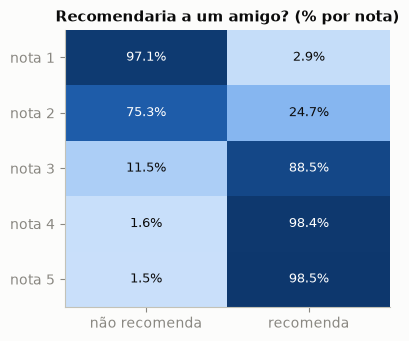

recommend_to_a_friend,No,Yes
overall_rating,,
1,26574,795
2,6321,2068
3,1879,14434
4,508,31837
5,705,47234


In [25]:
recommend = pd.crosstab(df["overall_rating"], df["recommend_to_a_friend"])
recommend_pct = (100 * recommend.div(recommend.sum(axis=1), axis=0)).round(1)

fig, ax = plt.subplots(figsize=(4.2, 3.6))
cmap = LinearSegmentedColormap.from_list("blue_ramp", BLUE_RAMP)
ax.imshow(recommend_pct.values, cmap=cmap, vmin=0, vmax=100, aspect="auto")
for (i, j), value in pd.DataFrame(recommend_pct.values).stack().items():
    # Texto claro só sobre as células escuras, para o número continuar legível.
    ax.text(j, i, f"{value:.1f}%", ha="center", va="center", fontsize=9,
            color="#ffffff" if value > 55 else "#0b0b0b")
ax.set_xticks(range(2), labels=["não recomenda", "recomenda"])
ax.set_yticks(range(5), labels=[f"nota {r}" for r in recommend_pct.index])
ax.grid(False)
ax.set_title("Recomendaria a um amigo? (% por nota)")
fig.savefig(FIG_DIR / "eda_rating_vs_recommend.png")
plt.show()
recommend

In [26]:
strong = recommend.loc[1, "Yes"] + recommend.loc[5, "No"]
print("contradições fortes (nota 1 + recomenda, nota 5 + não recomenda):", fmt(strong),
      f"({100 * strong / recommend.values.sum():.1f}%)")

contradições fortes (nota 1 + recomenda, nota 5 + não recomenda): 1.500 (1.1%)


**O que os números dizem**

- Nas pontas, nota e recomendação concordam quase sempre: só ~1,1% das resenhas tem contradição
  forte. É ruído, mas pouco.
- O meio é ambíguo: **a nota 3 é recomendada por ~88%** e a nota 2 por ~25%. Ou seja, a nota 3 do
  B2W puxa para o positivo. Isso afeta o classificador de 3 classes do charter: a classe neutra é
  a menor (12,3%) **e** a mais confundível com a positiva.

**Decisão**

- A nota continua sendo o rótulo, e **nada é removido por causa da recomendação**. Filtrar por uma
  segunda variável seria uma decisão de modelagem, e ela mudaria a distribuição que queremos
  imitar. Fica registrada como experimento possível na Etapa 3.
- Na avaliação, esperar a pior coerência na nota 3 e analisar a matriz de confusão do classificador
  antes de culpar o gerador.

## 5. Dados pessoais no texto livre

**Pergunta:** o cliente escreveu e-mail, CPF, telefone ou link na resenha? Procuramos no título e no
texto. Antes de contar, **provamos que cada regex funciona** num exemplo inventado: um zero só vale
como evidência se o detector é capaz de achar alguma coisa.

In [27]:
PII_PATTERNS = {
    "e-mail": r"[\w.+-]+@[\w-]+\.[\w.-]+",
    "CPF": r"\b\d{3}\.?\d{3}\.?\d{3}-?\d{2}\b",
    "telefone": r"(?:\(?\b\d{2}\)?\s?)?\b9?\d{4}[-\s]?\d{4}\b",
    "URL": r"https?://\S+|www\.\S+",
}
SYNTHETIC_EXAMPLES = {
    "e-mail": "fale comigo em fulano.teste@exemplo.com",
    "CPF": "meu cpf é 123.456.789-09",
    "telefone": "liga no (11) 98765-4321",
    "URL": "veja em https://exemplo.com/produto",
}
for name, pattern in PII_PATTERNS.items():
    assert re.search(pattern, SYNTHETIC_EXAMPLES[name]), f"regex de {name} não funciona"
print("os 4 detectores acham os exemplos inventados")


def mask(text: str) -> str:
    """Troca letras por x e dígitos por 9: mostra o formato sem mostrar o conteúdo."""
    return re.sub(r"[A-Za-zÀ-ÿ]", "x", re.sub(r"\d", "9", text))


free_text = df["review_title"].fillna("") + " " + df["review_text"].fillna("")
rows = []
for name, pattern in PII_PATTERNS.items():
    matches = free_text.str.extract(f"({pattern})")[0].dropna()
    rows.append(
        {
            "tipo": name,
            "resenhas": len(matches),
            "exemplos mascarados": " | ".join(mask(m)[:30] for m in matches.head(3)) or "-",
        }
    )
pd.DataFrame(rows)

os 4 detectores acham os exemplos inventados


,tipo,resenhas,exemplos mascarados
0,e-mail,0,-
1,CPF,0,-
2,telefone,0,-
3,URL,88,xxxx://xxxxxxxxxx.xxx/xxxxxx/x | xxxxx://xxx.xxxxxxx.xxx/xxxxx? | xxxxx://xxx.xxxxxxxx...


In [28]:
# Sequências longas de dígitos que escaparam dos padrões acima: qual é o formato delas?
digit_runs = free_text.str.findall(r"\d[\d .()/-]{6,}\d")
shapes = Counter(mask(run) for runs in digit_runs for run in runs)
pd.Series(dict(shapes.most_common(8)), name="ocorrências").to_frame()

,ocorrências
99/99/9999,1390
99/99/99,615
99.99.9999,51
99-99-9999,45
99/99/9999 99,43
99.99.99,29
99-99-99,19
99/9/9999,15


**O que os números dizem**

- **Nenhum e-mail, CPF ou telefone** aparece, mesmo com detectores que comprovadamente funcionam.
  As sequências numéricas longas têm formato de **data** (`99.99.9999`, `99-99-9999`). Os 22 textos
  com `@` usam o símbolo como palavrão censurado ("@#%$"), não como e-mail.
- Há **88 URLs**, em geral links para outras lojas ou fotos do produto.
- **Limite importante:** regex não detecta **nome de pessoa**. Há resenhas que mencionam "meu
  nome" ao contar um problema com o pedido. Isso vai para a seção de limitações e ética do
  relatório.

**Decisão**

- Os filtros de e-mail, CPF e telefone **continuam na limpeza**, como rede de segurança barata e
  testada (a limpeza da 1.5 também vale para dados futuros), mesmo que hoje não encontrem nada.
- **URLs são removidas**: podem apontar para páginas pessoais, e o modelo não deve aprender a gerar
  links.

## 6. Variedade: como o texto está escrito?

**Pergunta:** o que no texto pode atrapalhar o tokenizador ou o modelo? Cada caso abaixo vira uma
regra de normalização ou uma decisão consciente de não mexer.

In [29]:
text = reviews["review_text"]
variety_patterns = {
    "letra repetida 4+ vezes (muuuuito)": r"([A-Za-zÀ-ÿ])\1{3,}",
    "emoji ou símbolo fora do alfabeto latino": r"[^\x00-\u024F\s\u2000-\u206F\u20AC]",
    "tabulação ou \\r": r"[\t\r]",
    "tag HTML": r"<[A-Za-z/][^>]*>",
    "3+ asteriscos seguidos": r"\*{3,}",
}
counts = {name: text.str.contains(pat, regex=True).sum() for name, pat in variety_patterns.items()}
all_caps = (text.str.len() >= 20) & (text == text.str.upper()) & text.str.contains(r"[A-Za-z]")
counts["só em CAIXA ALTA (20+ caracteres)"] = all_caps.sum()
pd.Series(counts, name="resenhas").map(fmt).to_frame()

C:\Users\marku\AppData\Local\Temp\ipykernel_9060\1430793707.py:9: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  counts = {name: text.str.contains(pat, regex=True).sum() for name, pat in variety_patterns.items()}


,resenhas
letra repetida 4+ vezes (muuuuito),1.484
emoji ou símbolo fora do alfabeto latino,147
tabulação ou \r,17
tag HTML,3
3+ asteriscos seguidos,74
só em CAIXA ALTA (20+ caracteres),3.774


In [30]:
# Quais palavras têm letra esticada? Mostra se é ênfase (vale guardar) ou erro de digitação.
stretched_words = text.str.extractall(r"(\b\w*([A-Za-zÀ-ÿ])\2{3,}\w*\b)")[0].str.lower()
stretched_words.value_counts().head(10).rename("vezes").to_frame()

,vezes
0,
uhuuuuu,162
kkkk,76
kkkkk,54
ameiiii,46
kkkkkk,29
xxxxxx,27
xxxxx,27
xxxxxxx,25
xxxxxxxxxxx,23


**O que os números dizem**

- Letras esticadas aparecem em ~1.500 resenhas e quase sempre são **ênfase** ("muuuito",
  "ótimooo"). É estilo de resenha real, mas cada comprimento diferente ("muuuito", "muuuuuito")
  vira uma variação a mais para o tokenizador aprender.
- Caixa alta inteira aparece em ~3.900 resenhas, também como ênfase ou hábito.
- Emojis, tabulações e tags são raros (centenas ou menos).

**Decisão**

- **Normalizar Unicode (NFC)** e **espaços** (tabulação, `\r` e espaços múltiplos viram um espaço
  só), para que o mesmo texto tenha uma única representação em bytes.
- **Limitar letra repetida a 3** ("muuuuuito" vira "muuuito"): mantém a ênfase e corta variações
  inúteis.
- **Manter caixa e acentos**: a saída precisa parecer resenha real, e o BPE dá conta das duas
  formas. Passar tudo para minúsculas perderia a ênfase e o "jeito" do texto.
- **Remover emojis, símbolos fora do alfabeto latino e tags HTML**: são raros, então custam pouco
  ao corpus e evitam dezenas de símbolos que o modelo veria pouquíssimas vezes.

## 7. Produtos: como as resenhas se distribuem?

**Pergunta:** o split é por produto. Se poucos produtos concentram muitas resenhas, a fração de
resenhas em cada conjunto pode ficar bem diferente da fração de produtos.

In [31]:
per_product = df["product_id"].value_counts()
print("produtos:", fmt(len(per_product)))
print("produtos com 1 resenha:", fmt((per_product == 1).sum()))
print(f"resenhas nos 100 maiores produtos: {100 * per_product.head(100).sum() / len(df):.1f}%")
per_product.describe(percentiles=[0.5, 0.9, 0.99]).round(1)

produtos: 48.001
produtos com 1 resenha: 34.231
resenhas nos 100 maiores produtos: 16.7%


count    48001.0
mean         2.8
std         12.9
min          1.0
50%          1.0
90%          4.0
99%         29.0
max        792.0
Name: count, dtype: float64

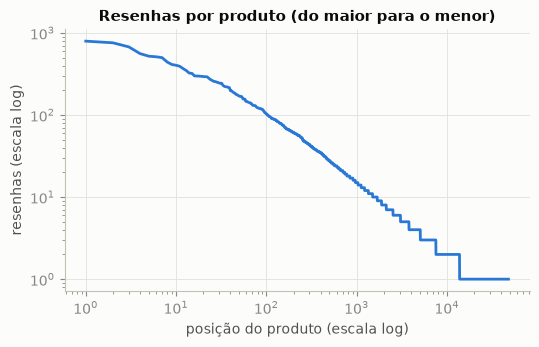

In [32]:
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.loglog(range(1, len(per_product) + 1), per_product.values, color=BLUE, linewidth=2)
ax.set_title("Resenhas por produto (do maior para o menor)")
ax.set_xlabel("posição do produto (escala log)")
ax.set_ylabel("resenhas (escala log)")
fig.savefig(FIG_DIR / "eda_reviews_per_product.png")
plt.show()

**O que os números dizem**

- É uma **cauda longa**: a mediana é 1 resenha por produto (71% dos produtos têm uma só), mas o
  maior tem quase 800, e os 100 maiores somam ~17% das resenhas.
- Se um produto gigante cair no teste, sozinho ele vira uma fatia grande do teste e puxa o estilo
  das resenhas dele (por exemplo, um único modelo de celular).

**Decisão**

- No split (1.5), sortear **produtos** com semente fixa e depois **conferir** a fração de resenhas e
  a distribuição de notas em cada conjunto. Se a fração fugir muito do alvo, refazer com outra
  regra (por exemplo, distribuir os produtos grandes primeiro), e não escolher a semente que
  "dá certo".
- Limitar resenhas por produto fica como **experimento** da Etapa 3, e não como regra de limpeza.

## 8. Título: junto com o texto ou fora?

In [33]:
titles = df["review_title"].fillna("")
print("mediana de palavras no título:", titles.str.split().str.len().median())
print("título igual ao texto:", fmt((titles.str.lower() == df["review_text"].str.lower()).sum()))
titles.str.lower().value_counts().head(10).rename("vezes").to_frame()

mediana de palavras no título: 2.0
título igual ao texto: 316


,vezes
review_title,
muito bom,4299
excelente,3231
ótimo produto,2323
ótimo,2011
bom,1912
gostei muito do produto,1581
gostei,1538
gostei do produto,1400
excelente produto,1377


**Decisão:** a v1 gera **só o texto**. O título é curto (mediana de 2 palavras), muito repetido
("ótimo", "excelente") e às vezes idêntico ao texto. Colocá-lo junto mudaria o formato da saída sem
trazer informação nova. Ele **não entra** em `data/processed`. Se um dia for útil, pode ser
recuperado de `data/raw`.

## 9. Contexto: período e categorias

Só descritivo: a categoria é uma extensão futura e o split não é temporal.

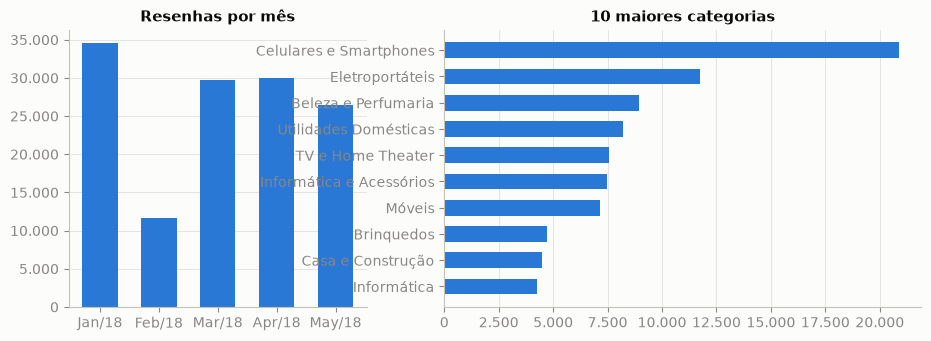

In [34]:
months = pd.to_datetime(df["submission_date"]).dt.to_period("M").value_counts().sort_index()
categories = df["site_category_lv1"].value_counts().head(10).sort_values()

fig, (ax_month, ax_cat) = plt.subplots(1, 2, figsize=(11, 3.6), width_ratios=[1, 1.6])
ax_month.bar(months.index.strftime("%b/%y"), months.values, color=BLUE, width=0.6)
ax_month.set_title("Resenhas por mês")
ax_month.yaxis.set_major_formatter(lambda v, _: fmt(v))
ax_month.grid(axis="x", visible=False)
ax_cat.barh(categories.index, categories.values, color=BLUE, height=0.6)
ax_cat.set_title("10 maiores categorias")
ax_cat.xaxis.set_major_formatter(lambda v, _: fmt(v))
ax_cat.grid(axis="y", visible=False)
fig.savefig(FIG_DIR / "eda_months_categories.png")
plt.show()

## 10. Prévia: quanto sobra depois da limpeza?

Uma estimativa com as regras das seções 2 e 3. A limpeza de verdade é feita na 1.5, em código
testado; aqui é só para saber se o corpus continua do tamanho esperado.

In [35]:
preview = reviews[(reviews["text_key"] != "") & ~reviews["text_key"].isin(conflicting.index)]
preview = preview.drop_duplicates("text_key")
print("resenhas:", fmt(len(preview)), f"({100 * len(preview) / len(df):.1f}% do bruto)")
print("palavras:", fmt(preview["n_words"].sum()))
(100 * preview["overall_rating"].value_counts(normalize=True).sort_index()).round(1).rename(
    "fração (%)"
).to_frame()

resenhas: 126.120 (95.3% do bruto)
palavras: 2.890.694


,fração (%)
overall_rating,
1,19.5
2,6.3
3,12.5
4,25.0
5,36.6


## Decisões para a limpeza (1.5) e para a Etapa 2

| # | Decisão | Por quê | Seção |
|---|---|---|---|
| 1 | Descartar `reviewer_id`, `reviewer_birth_year`, `reviewer_gender`, `reviewer_state` | Dados pessoais que o modelo não usa | 0 |
| 2 | Remover linhas sem `review_text` | O texto é o alvo da geração | 2 |
| 3 | Remover URLs; manter filtros de e-mail, CPF e telefone (com testes) | Privacidade; hoje achamos 0 e-mail/CPF/telefone e 88 URLs | 5 |
| 4 | Normalizar Unicode (NFC) e espaços; remover emojis, símbolos não latinos e tags HTML | Uma representação por texto; símbolos raros só inflariam o vocabulário | 6 |
| 5 | Limitar letra repetida a 3 | Mantém a ênfase, corta variações inúteis | 6 |
| 6 | Manter caixa e acentos | A saída precisa parecer resenha real | 6 |
| 7 | Remover textos que viram vazio na normalização | Não há palavra para aprender | 3 |
| 8 | Remover todas as ocorrências de textos com notas diferentes | Mesmo texto com dois rótulos | 3 |
| 9 | Deduplicar pela chave normalizada no corpus inteiro, **antes do split** | Texto-modelo em produtos diferentes vazaria entre treino e teste | 3 |
| 10 | Split por produto com semente fixa, conferindo fração de resenhas e de notas por conjunto | Cauda longa de produtos | 7 |
| 11 | Gerar só o texto; título fora de `data/processed` | Título curto e redundante | 8 |
| 12 | Sem filtro por `recommend_to_a_friend` | Seria decisão de modelagem; vira experimento possível na Etapa 3 | 4 |
| 13 | Corte de tamanho só na Etapa 2, em tokens (referência: ~128 tokens) | O tamanho real depende do BPE | 1 |

**Limitações registradas para o relatório:** regex não detecta nomes de pessoas no texto; a nota 3
do B2W puxa para o positivo, o que torna a classe neutra a mais difícil; ~1,1% das resenhas tem nota
e recomendação em contradição forte.